<a href="https://colab.research.google.com/github/YKochura/mld-kpi/blob/main/tutor/gnn/introduction_to_graph_neural_networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 <img src="https://raw.githubusercontent.com/YKochura/mld-kpi/521625691a8ffb4b44b818f2da22b9592820a9c8/tutor/gnn/images/DLI_Header.png" alt="Header" style="width: 400px;"/>

# Вступ до графових нейронних мереж


У цьому туторіалі Ви ознайомитесь з основними поняттями графів та графових нейронних мереж.

**Зміст**
<br>
Цей блокнот охоплює такі розділи:
1. [Вступ до графів](#s1-1)
    * [Робота з графовими даними](#s1-1.1)
    * [Вправа №1 — побудова простого графа](#s1-e1)
    * [Маніпулювання ознаками вершин і ребер](#s1-1.2)
    * [Представлення графових даних](#s1-1.3)
2. [Огляд набору даних](#s1-2)
    * [Розвідувальний аналіз даних](#s1-2.1)
    * [Вправа №2 — пошук вершини з найбільшою кількістю зв'язків](#s1-e2)
    * [Підготовка даних і підграф](#s1-2.2)
3. [Побудова графових нейронних мереж для класифікації вершин](#s1-3)
    * [Передача повідомлень і графова згортка](#s1-3.1)
4. [Побудова GNN за допомогою PyTorch](#s1-4)
    * [Sum-pooling (пулінг за сумою)](#s1-4.1)
    * [Базова модель MLP](#s1-4.2)
    * [Вправа №3 — mean-pooling (пулінг за середнім)](#s1-e3)
    * [GCN, графова згорткова мережа](#s1-4.3)
5. [Побудова GNN за допомогою вбудованих модулів DGL](#s1-5)
    * [GraphConv](#s1-5.1)

<a name='s1-1'></a>
## Вступ до графів ##
Граф — це структура даних, що складається з **вершин** (вузлів) і **ребер**. Вершина може представляти особу, місце чи об'єкт, а ребра задають відношення між вершинами. Ребра можуть бути орієнтованими, коли в ребра є початкова та кінцева вершини. Вони також можуть бути неорієнтованими, коли поняття початкової чи кінцевої вершини відсутнє. Графи добре підходять для розв'язання складних задач, що містять відношення та взаємодії.

До даних, які природно представляються графами, належать:
* **Мережі цитувань**, що дають змогу досліджувати взаємозв'язки між публікаціями.
* **Соціальні мережі** — інструменти для вивчення закономірностей колективної поведінки людей, установ і організацій. Граф соціальної мережі представляє групи людей, моделюючи окремих осіб як вершини, а їхні відносини як ребра.
* **Молекули**, які можна описати як граф, де вершини — це атоми, а ребра — хімічні зв'язки між ними.

Структура графів може суттєво відрізнятися за кількістю вершин, ребер і за зв'язністю вершин.

До властивостей, які вирізняють графи серед інших типів даних, належать:
1. Граф існує в неевклідовому просторі, що ускладнює інтерпретацію даних. Для візуалізації даних використовують різні методи зниження розмірності.
2. Графи є неструктурованими й не мають фіксованої форми.
3. Їхній великий розмір і висока розмірність ускладнюють інтерпретацію людиною.

<a name='s1-1.1'></a>
### Робота з графовими даними ###
У цьому туторіалі ми використаємо відкриту бібліотеку Deep Graph Library, [DGL](https://www.dgl.ai/), та [PyTorch](https://pytorch.org/) для роботи з графовими даними. Серед інших популярних бібліотек глибинного навчання на графах — [Spektral](https://graphneural.network/), [Graph Nets](https://www.deepmind.com/open-source/graph-nets) та [PyTorch Geometric](https://www.pyg.org/), які дають змогу маніпулювати графовими даними подібним чином.

DGL представляє кожну вершину унікальним цілим числом, яке називають ідентифікатором вершини (node ID), а кожне ребро — парою цілих чисел, що відповідають ідентифікаторам його кінцевих вершин. DGL присвоює кожному ребру унікальне ціле число, яке називають ідентифікатором ребра (edge ID), відповідно до порядку, в якому ребро було додане до графа, починаючи з `0`. У DGL усі ребра є орієнтованими, а ребро `(u, v)` означає, що напрямок іде від початкової вершини `u` до кінцевої вершини `v`. Під час побудови **неорієнтованих** графів ребра можна розглядати як **двоспрямовані**, додаючи **зворотні ребра**.

Спочатку створимо нижче приклад графа:

<p><img src='https://raw.githubusercontent.com/YKochura/mld-kpi/521625691a8ffb4b44b818f2da22b9592820a9c8/tutor/gnn/images/sample_graph_1.png' width=240></p>

Об'єкт [`DGLGraph`](https://www.dgl.ai/dgl_docs/api/python/dgl.DGLGraph.html) можна створити за допомогою [`dgl.graph(data)`](https://www.dgl.ai/dgl_docs/generated/dgl.graph.html), яка приймає пару ідентифікаторів вершин `(U, V)`, що задають початкову(-і) та кінцеву(-і) вершину(-и). Після створення графа для звернення до вершин і ребер можна використовувати [`dgl.DGLGraph.nodes()`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.nodes.html), [`dgl.DGLGraph.edges()`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.edges.html) або [`dgl.DGLGraph.edge_ids(u, v)`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.edge_ids.html). Ребра також можна ідентифікувати за допомогою [`dgl.DGLGraph.find_edges(eid)`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.find_edges.html), [`dgl.DGLGraph.in_edges(v)`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.in_edges.html) або [`dgl.DGLGraph.out_edges(u)`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.out_edges.html). Щоб визначити степінь вершини, тобто кількість її зв'язків, можна скористатися [`dgl.DGLGraph.in_degrees(v)`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.in_degrees.html) або [`dgl.DGLGraph.out_degrees(u)`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.out_degrees.html). За бажанням для візуалізації невеликих графів можна використати [`networkx`](https://networkx.org/).

_Примітка: докладніше про API `DGLGraph`, зокрема про [запити до базових властивостей структури графа](https://www.dgl.ai/dgl_docs/api/python/dgl.DGLGraph.html#querying-graph-structure), можна дізнатися [тут](https://www.dgl.ai/dgl_docs/api/python/dgl.DGLGraph.html)._

In [1]:
!pip install torch==2.4.0 torchvision==0.19.0 torchaudio==2.4.0 --index-url https://download.pytorch.org/whl/cu124
!pip install dgl -f https://data.dgl.ai/wheels/torch-2.4/cu124/repo.html
!pip install torchdata==0.8.0 pydantic pandas pyyaml

Looking in indexes: https://download.pytorch.org/whl/cu124
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.3/797.3 MB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 100.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 41.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.7/24.7 MB 186.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.4/883.4 kB 172.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 225.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.0/363.0 MB 46.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 109.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 107.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.4/128.4 MB 83.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207

In [18]:
!pip install ogb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 kB 10.7 MB/s eta 0:00:00


In [2]:
# DO NOT CHANGE THIS CELL
# import dependencies
import dgl
import torch

DGL backend not selected or invalid.  Assuming PyTorch for now.


Setting the default backend to "pytorch". You can change it in the ~/.dgl/config.json file or export the DGLBACKEND environment variable.  Valid options are: pytorch, mxnet, tensorflow (all lowercase)


In [3]:
# DO NOT CHANGE THIS CELL
# створити початкові вершини для ребер (2, 1), (3, 2), (4, 3)
sample_u=[2, 3, 4]

# створити кінцеві вершини для ребер (2, 1), (3, 2), (4, 3)
sample_v=[1, 2, 3]

# створити граф
sample_g=dgl.graph((sample_u, sample_v))

# вивести граф
print(sample_g)

Graph(num_nodes=5, num_edges=3,
      ndata_schemes={}
      edata_schemes={})


In [4]:
# DO NOT CHANGE THIS CELL
# вивести ідентифікатори вершин
print("Ідентифікатори вершин: \n{}\n".format(sample_g.nodes()))

# вивести початкову та кінцеву вершини кожного ребра
print("Початкові та кінцеві вершини кожного ребра: \n{}\n".format(sample_g.edges()))

# вивести ідентифікатори ребер
print("Ідентифікатори ребер: \n{}".format(sample_g.edge_ids(sample_u, sample_v)))

Ідентифікатори вершин: 
tensor([0, 1, 2, 3, 4])

Початкові та кінцеві вершини кожного ребра: 
(tensor([2, 3, 4]), tensor([1, 2, 3]))

Ідентифікатори ребер: 
tensor([0, 1, 2])


In [5]:
# DO NOT CHANGE THIS CELL
# побудувати двоспрямований граф
sample_g=dgl.to_bidirected(sample_g)

# dgl.add_reverse_edges(graph) дає подібний результат
# sample_g=dgl.add_reverse_edges(sample_g)

# вивести властивості графа
print("Ідентифікатори вершин: \n{}\n".format(sample_g.nodes()))
print("Початкові та кінцеві вершини кожного ребра: \n{}\n".format(sample_g.edges()))
print("Ідентифікатори ребер для орієнтованого графа: \n{}\n".format(sample_g.edge_ids(sample_u, sample_v)))

# вивести всі ребра
print("Ідентифікатори ребер для двоспрямованого/неорієнтованого графа: \n{}".format(sample_g.edge_ids(sample_u+sample_v, sample_v+sample_u)))

Ідентифікатори вершин: 
tensor([0, 1, 2, 3, 4])

Початкові та кінцеві вершини кожного ребра: 
(tensor([1, 2, 2, 3, 3, 4]), tensor([2, 1, 3, 2, 4, 3]))

Ідентифікатори ребер для орієнтованого графа: 
tensor([1, 3, 5])

Ідентифікатори ребер для двоспрямованого/неорієнтованого графа: 
tensor([1, 3, 5, 0, 2, 4])


In [6]:
# DO NOT CHANGE THIS CELL
# знайти всі ребра, з'єднані з вершиною 1
node_id=1
print("Початкові вершини {0[0]} з'єднані з кінцевими вершинами {0[1]}. ".format(sample_g.in_edges(node_id)))

Початкові вершини tensor([2]) з'єднані з кінцевими вершинами tensor([1]). 


In [7]:
# DO NOT CHANGE THIS CELL
# отримати степені вершин
print("Степені всіх вершин: \n{}".format(sample_g.in_degrees()))

Степені всіх вершин: 
tensor([0, 1, 2, 2, 1])


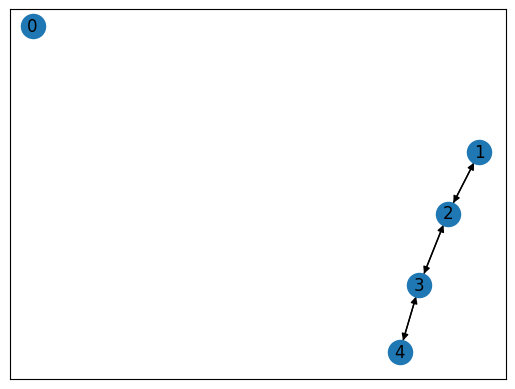

In [8]:
# DO NOT CHANGE THIS CELL
# візуалізувати граф
import networkx as nx

# намалювати граф за допомогою networkx
G=dgl.to_networkx(sample_g)
nx.draw_networkx(G)

_Примітка: цей граф складається з 5 вершин і 3 ребер. Кількість вершин автоматично визначається за найбільшим ідентифікатором вершини в заданих ребрах. Крім того, ідентифікатори ребер нумеруються автоматично відповідно до порядку їх додавання, а для двоспрямованих/неорієнтованих графів кожне ребро враховується двічі._

<a name='s1-e1'></a>
### Вправа №1 — побудова простого графа ###
Створімо наведений нижче граф.

<p><img src='https://raw.githubusercontent.com/YKochura/mld-kpi/521625691a8ffb4b44b818f2da22b9592820a9c8/tutor/gnn/images/sample_graph_2.png' width=240></p>

**Інструкції**:<br>
* Змініть лише місця з `<<<<FIXME>>>>`, щоб створити приклад графа.

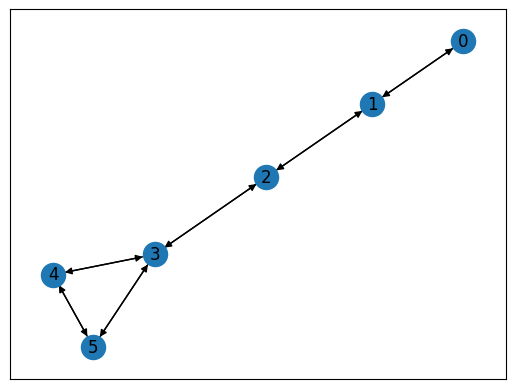

In [11]:
# створити початкові та кінцеві вершини
u = <<<<FIXME>>>
v = <<<<FIXME>>>
g = dgl.graph((u, v))

# під час побудови неорієнтованих графів ребра розглядаються як двоспрямовані
g = dgl.to_bidirected(g)

# намалювати граф за допомогою networkx
nx.draw_networkx(dgl.to_networkx(g))

<a name='s1-1.2'></a>
### Маніпулювання ознаками вершин і ребер ###
Багато графових даних містять ознаки (атрибути) вершин і ребер. Ми можемо призначати та отримувати ознаки вершин і ребер через інтерфейси [`dgl.DGLGraph.ndata`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.ndata.html) та [`dgl.DGLGraph.edata`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.edata.html) подібно до того, як додаємо чи отримуємо пари «ключ — значення» в [словнику Python](https://docs.python.org/3/tutorial/datastructures.html#dictionaries). Крім того, `ndata` та `edata` можна використовувати для зберігання інших даних рівня вершин і ребер, потрібних для глибинного навчання, наприклад міток (`labels`) і масок для навчальної та тестової вибірок (`train`/`test masks`). Також граф загалом може мати глобальні властивості.

_Примітка: DGLGraph приймає лише ознаки, збережені як числові [тензори](https://pytorch.org/docs/stable/tensors.html). Стрімкий розвиток глибинного навчання надав нам багато способів кодування різних типів атрибутів у числові ознаки._

In [12]:
# вивести ndata
print("Дані вершин: \n{}\n".format(g.ndata))

# вивести edata
print("Дані ребер: \n{}".format(g.edata))

Дані вершин: 
{}

Дані ребер: 
{}


Нижче ми демонструємо призначення випадкових значень як векторів ознак вершин. Ми використовуємо функцію [`dgl.DGLGraph.num_nodes()`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.num_nodes.html), щоб отримати кількість вершин у нашому графі, а потім призначаємо випадковий багатовимірний вектор ознак вершин із назвою `feat` за допомогою `dgl.DGLGraph.ndata`. Подібні присвоєння можна виконати й для ребер за допомогою [`dgl.DGLGraph.num_edges()`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.num_edges.html) та `dgl.DGLGraph.edata`.

_Примітка: ознаки вершин і ребер можуть мати будь-які назви, так само як і ключі словника Python можуть бути довільними. Наприклад, ознаку вершин можна було б назвати `f_n` замість `feat`._

In [13]:
# DO NOT CHANGE THIS CELL
# отримати кількість вершин
num_nodes=g.num_nodes()

# призначити кожній вершині 4-вимірний випадковий вектор ознак feat
g.ndata['feat']=torch.randn(num_nodes, 4)

# вивести ознаки вершин
print("Ознаки вершин ({}): \n{}\n".format(g.ndata['feat'].shape, g.ndata))

# призначити кожному ребру 5-вимірний випадковий вектор ознак f_e
num_edges=g.num_edges()
g.edata['f_e']=torch.randn(num_edges, 5)
print("Ознаки ребер ({}): \n{}".format(g.edata['f_e'].shape, g.edata))

Ознаки вершин (torch.Size([6, 4])): 
{'feat': tensor([[ 0.2749, -0.1071, -1.8131,  0.4743],
        [ 1.2809, -1.3444,  0.7272, -1.3417],
        [ 0.9400,  0.2407, -1.0579, -0.8445],
        [ 0.5684,  0.3646, -1.2449,  2.3898],
        [ 0.5484, -0.3936, -1.9579,  0.0620],
        [-0.4956,  1.2317,  0.0665, -0.6445]])}

Ознаки ребер (torch.Size([12, 5])): 
{'f_e': tensor([[-0.2681, -0.1415, -0.9996,  0.2965,  0.0164],
        [-0.8802, -0.4843, -0.6863, -0.4937, -0.8467],
        [-0.6696,  0.6153, -0.8393, -0.7064, -1.5122],
        [ 1.2095,  1.1300,  1.7821, -0.4388,  0.7652],
        [ 0.8043,  1.9399,  0.4627,  0.9993, -0.6100],
        [ 1.8390, -0.0172, -0.0540,  0.9532,  0.6372],
        [-1.2892, -2.0781,  0.6349, -0.4246,  0.4574],
        [-0.2163, -0.0689, -0.8683, -0.1806, -0.0839],
        [-1.2148, -1.9341, -1.2105, -0.4104,  2.5553],
        [ 0.3263,  1.7399, -0.2810, -0.2136,  0.3018],
        [-1.2060,  0.7110,  0.5330, -0.4854, -0.6416],
        [-0.6245,  0.0687

<a name='s1-1.3'></a>
### Представлення графових даних ###
Граф часто представляють за допомогою **матриці суміжності**. Якщо граф має `n` вершин, то матриця суміжності має розмірність `n` x `n`. Матриця містить значення `0/1`, які вказують, чи існує зв'язок між початковою та кінцевою вершинами. Хоча [`dgl.DGLGraph.adj()`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.adj.html) повертає [розріджений тензор](https://pytorch.org/docs/stable/sparse.html), його можна додатково перетворити на щільний тензор, щоб він був наочнішим. Для нашого графа матриця суміжності виглядає так:

<p><img src='https://raw.githubusercontent.com/YKochura/mld-kpi/521625691a8ffb4b44b818f2da22b9592820a9c8/tutor/gnn/images/adj_matrix.png' width=240></p>

Проте, хоча візуалізація структури графа у вигляді матриці суміжності може бути зручною та інтуїтивною, зазвичай вона неефективна, якщо матриця розріджена (здебільшого заповнена нулями). Інший спосіб представлення ребер — **списки суміжності**. Вони описують зв'язки між вершинами як кортеж одновимірних тензорів `(v, u)`, що містять кінцеві та початкові вершини всіх ребер.

In [14]:
# DO NOT CHANGE THIS CELL
# вивести матрицю суміжності як розріджений тензор
print("Матриця суміжності (розріджений тензор): \n{}\n".format(g.adj()))

# вивести матрицю суміжності як щільний тензор
print("Матриця суміжності (щільний тензор): \n{}".format(g.adj().to_dense()))

Матриця суміжності (розріджений тензор): 
SparseMatrix(indices=tensor([[0, 1, 1, 2, 2, 3, 3, 3, 4, 4, 5, 5],
                             [1, 0, 2, 1, 3, 2, 4, 5, 3, 5, 3, 4]]),
             values=tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]),
             shape=(6, 6), nnz=12)

Матриця суміжності (щільний тензор): 
tensor([[0., 1., 0., 0., 0., 0.],
        [1., 0., 1., 0., 0., 0.],
        [0., 1., 0., 1., 0., 0.],
        [0., 0., 1., 0., 1., 1.],
        [0., 0., 0., 1., 0., 1.],
        [0., 0., 0., 1., 1., 0.]])


In [15]:
# DO NOT CHANGE THIS CELL
# обчислити степені вершин вручну та використати .long() для перетворення на цілі числа
g.ndata['degree']=g.adj().to_dense().sum(axis=1).long()

# вивести степені вершин
print("Степені вершин, обчислені вручну: \n{}\n".format(g.ndata['degree']))

# степені вершин також можна отримати за допомогою API DGL
print("Степені вершин за допомогою API DGL: \n{}".format(g.in_degrees()))

# ознаки також можна видаляти, аналогічно до елементів словника
del g.ndata['degree']

Степені вершин, обчислені вручну: 
tensor([1, 2, 2, 3, 2, 2])

Степені вершин за допомогою API DGL: 
tensor([1, 2, 2, 3, 2, 2])


In [16]:
# DO NOT CHANGE THIS CELL
# вивести кінцеві та початкові вершини всіх ребер як списки суміжності
u=g.edges()[0].tolist()
v=g.edges()[1].tolist()
print("Ребра: \n{}".format(list(zip(u, v))))

Ребра: 
[(0, 1), (1, 0), (1, 2), (2, 1), (2, 3), (3, 2), (3, 4), (3, 5), (4, 3), (4, 5), (5, 3), (5, 4)]


<a name='s1-2'></a>
## Огляд набору даних ##
Для реалістичної демонстрації ми використовуємо набір даних [`ogbn-arxiv`](https://ogb.stanford.edu/docs/nodeprop/#ogbn-arxiv) з [**O**pen **G**raph **B**enchmark](https://ogb.stanford.edu/). Набір `ogbn-arxiv` є орієнтованим графом, що представляє мережу цитувань між статтями з комп'ютерних наук (CS) на arXiv. Кожна вершина — це стаття на arXiv, а кожне орієнтоване ребро означає, що одна стаття цитує іншу. До кожної статті додається 128-вимірний вектор ознак [word2vec](https://en.wikipedia.org/wiki/Word2vec). Це чудовий приклад того, як GNN можна використовувати для вилучення інформації, закладеної в графах, з метою прогнозування.

Кожна вершина належить до однієї з 40 тематичних категорій статей з комп'ютерних наук на arXiv, наприклад cs.AI, cs.LG і cs.OS, які вручну визначають і позначають автори статей та модератори arXiv.

Хоча деякі набори даних можуть містити більше одного графа, набір `ogbn-arxiv` містить єдиний граф з індексом `0`.

In [19]:
# DO NOT CHANGE THIS CELL
# імпортувати залежності
from ogb.nodeproppred import DglNodePropPredDataset

# завантажити дані
dataset=DglNodePropPredDataset(name='ogbn-arxiv')

# призначити граф і мітки
g, labels=dataset[0]
print(g)

Downloaded 0.08 GB: 100%|██████████| 81/81 [00:25<00:00,  3.19it/s]


Extracting dataset/arxiv.zip
Loading necessary files...
This might take a while.
Processing graphs...


100%|██████████| 1/1 [00:00<00:00, 3371.63it/s]


Converting graphs into DGL objects...


100%|██████████| 1/1 [00:00<00:00, 172.78it/s]

Saving...


Graph(num_nodes=169343, num_edges=1166243,
      ndata_schemes={'year': Scheme(shape=(1,), dtype=torch.int64), 'feat': Scheme(shape=(128,), dtype=torch.float32)}
      edata_schemes={})


<a name='s1-2.1'></a>
### Розвідувальний аналіз даних ###

Ми виконаємо базовий розвідувальний аналіз даних, щоб краще зрозуміти набір даних.

In [20]:
# DO NOT CHANGE THIS CELL
# вивести ключі вершин
print("Ключі словника вершин: \n{}\n".format(g.ndata.keys()))

# вивести розмірність ознак вершин
print("Розмірність ознак вершин (кількість_вершин x кількість_ознак): \n{}\n".format(g.ndata['feat'].shape))

# вивести кількість вершин
print("Кількість вершин: \n{}\n".format(g.num_nodes()))

# вивести кількість ребер
print("Кількість ребер: \n{}".format(g.num_edges()))

Ключі словника вершин: 
dict_keys(['year', 'feat'])

Розмірність ознак вершин (кількість_вершин x кількість_ознак): 
torch.Size([169343, 128])

Кількість вершин: 
169343

Кількість ребер: 
1166243


In [21]:
# DO NOT CHANGE THIS CELL
# вивести мітки
print("Розмірність міток: \n{}\n".format(labels.shape))
print("Класи міток: \n{}".format(labels.unique()))

Розмірність міток: 
torch.Size([169343, 1])

Класи міток: 
tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35,
        36, 37, 38, 39])


<a name='s1-e2'></a>
### Вправа №2 — пошук вершини з найбільшою кількістю зв'язків ###
Знайдімо вершину з найбільшим степенем.

**Інструкції**:<br>
* Змініть лише місце з `<<<<FIXME>>>>`, щоб знайти вершину з найбільшою кількістю зв'язків.

In [25]:
# змінні для ідентифікатора вершини з найбільшою кількістю зв'язків і самої кількості зв'язків
max_node_id=0
max_count=0

# перебрати всі вершини
for each_node in g.nodes():
    # перевірити, чи кількість зв'язків більша за поточний максимум
    count=len(g.<<<<FIXME>>>>(each_node)[0])
    if count > max_count:

        # оновити max_count і max_node_id
        max_count = count
        max_node_id = each_node

# вивести вершину з найбільшою кількістю зв'язків
print("Вершина Node_{} має найбільшу кількість зв'язків. ".format(max_node_id))

Вершина Node_1353 має найбільшу кількість зв'язків. 


In [26]:
# DO NOT CHANGE THIS CELL
# Степені вершин також можна отримати за допомогою `.in_degrees()` або `.out_degrees()`
print("Степені вершин за допомогою API DGL: \n{}\n".format(g.in_degrees()))

# вивести вершину з найбільшою кількістю зв'язків
print("Вершина Node_{} має найбільшу кількість зв'язків. ".format(torch.argmax(g.in_degrees())))

Степені вершин за допомогою API DGL: 
tensor([289,   1,   5,  ...,   1,   3,   0])

Вершина Node_1353 має найбільшу кількість зв'язків. 


<a name='s1-2.2'></a>
### Підготовка даних і підграф ###
Перш ніж використовувати набір даних для машинного навчання, ми виконаємо розбиття даних для валідації моделі. Початковий набір даних містить 169 343 вершини та 1 116 243 ребра. Ми розіб'ємо дані за датами публікації статей. Навчаючи модель на старіших статтях, ми можемо потім використовувати її для прогнозування міток нещодавно опублікованих статей. Це може бути надзвичайно корисним для модераторів arXiv. З огляду на часовий діапазон, який охоплюють наші дані, ми навчатимемо модель на статтях, опублікованих до 2017 року включно, валідуватимемо на статтях 2018 року, а тестуватимемо на статтях, опублікованих з 2019 року. Завантажувач даних OGB зручно надає нам безпосередньо маски `train`, `valid` і `test`.

Крім того, для демонстрації ми спочатку працюватимемо з підмножиною даних. Зокрема, оскільки для побудови наших перших GNN ми використовуватимемо щільну матрицю суміжності, обсяг доступної пам'яті дозволяє працювати лише з підмножиною вершин. DGL надає зручну функцію [`dgl.DGLGraph.subgraph(nodes)`](https://www.dgl.ai/dgl_docs/generated/dgl.DGLGraph.subgraph.html), яка допомагає це зробити. Відображення вершин/ребер підграфа на початковий граф можна отримати, звернувшись до ознаки вершин `dgl.NID` або ознаки ребер `dgl.EID` у новому графі. Функція `subgraph` також копіює початкові ознаки до підграфа. Коли ми зрозуміємо, як працюють GNN, ми зможемо навчати модель на розрідженій матриці суміжності для всього набору даних.

_Примітка: хоча набір даних `ogbn-arxiv` представляє орієнтований граф, ми проігноруємо напрямок ребер і розглядатимемо його як неорієнтований._

In [27]:
# DO NOT CHANGE THIS CELL
# імпортувати залежності
import numpy as np

# задати кількість класів міток
num_classes=6

# отримати підмножину індексів вершин
sub_nodes=np.where(np.isin(labels, range(num_classes)))[0]

# отримати підмножину міток
sub_labels=labels[np.isin(labels, range(num_classes))]

# отримати підграф і зробити його двоспрямованим/неорієнтованим
sub_g=g.subgraph(sub_nodes)
sub_g=dgl.to_bidirected(sub_g, copy_ndata=True)
print(sub_g)

# вивести ідентифікатори вершин у початковому графі
parent_nodes=sub_g.ndata[dgl.NID]
print("Ідентифікатори батьківських вершин: {}".format(parent_nodes))

Graph(num_nodes=18991, num_edges=64740,
      ndata_schemes={'year': Scheme(shape=(1,), dtype=torch.int64), 'feat': Scheme(shape=(128,), dtype=torch.float32), '_ID': Scheme(shape=(), dtype=torch.int64)}
      edata_schemes={})
Ідентифікатори батьківських вершин: tensor([     0,      1,      7,  ..., 169338, 169341, 169342])


In [28]:
# DO NOT CHANGE THIS CELL
# вибрати підмножини для навчальної, валідаційної та тестової вибірок за допомогою parent_nodes
year=sub_g.ndata['year'].flatten()
train_mask=sub_g.nodes()[year<=2017]
valid_mask=sub_g.nodes()[(year>2017)&(year<=2018)]
test_mask=sub_g.nodes()[year>2018]

print("{} вершин для навчання: \n{} вершин для валідації: \n{} вершин для тестування. ".format(len(train_mask), len(valid_mask), len(test_mask)))

11234 вершин для навчання: 
3014 вершин для валідації: 
4743 вершин для тестування. 


<a name='s1-3'></a>
## Побудова графових нейронних мереж для класифікації вершин ##
Графові дані становлять складність, оскільки стандартні методи глибинного навчання зосереджені переважно на структурованих даних, таких як піксельні сітки фіксованого розміру (зображення) та послідовності (текст). Графові нейронні мережі, або **GNN**, — це різні підходи до застосування глибинного навчання на графах, які:
* повною мірою використовують структуру графа;
* враховують масштабованість та ефективність залежно від розміру графа та його ознак;
* забезпечують простий спосіб виконання задач прогнозування на рівні вершин, ребер і графів.

<a name='s1-3.1'></a>
### Передача повідомлень і графова згортка ###
**Передача повідомлень** (*message passing*) — це механізм, за якого кожна вершина графа надсилає інформацію про себе своїм сусідам і отримує від них повідомлення у відповідь, щоб оновити свій стан і зрозуміти своє оточення. Він дає змогу графовим нейронним мережам досліджувати зв'язність графа, зіставляючи повідомлення (ознаки), надіслані сусідніми вершинами, для оновлення ознак вершини. Передача повідомлень є ядром бібліотеки DGL, і більшість графових обчислень у DGL ґрунтуються на ній. Передачу повідомлень можна розглядати як два основні кроки:
1. Перший крок — це етап «повідомлення» (*message*), на якому вершини надсилають або розсилають повідомлення своїм сусідам. Він виконується для всіх наявних або релевантних ребер графа.  
2. Другий крок — це етап «згортання» (*reduce*), на якому повідомлення **агрегуються** вершиною-отримувачем і використовуються для оновлення її ознак. Він виконується для всіх наявних або релевантних вершин графа.

**Графова [згортка](https://en.wikipedia.org/wiki/Convolution)** (*graph convolution*) поєднує інформацію з околів вершин і кодує оновлені ознаки вершин у *латентні представлення*. Її можна реалізувати на основі простого механізму передачі повідомлень, що передбачає лінійну комбінацію ознак околу, де ваги, які використовуються для агрегації, залежать лише від структури графа.
* [Вкладення](https://en.wikipedia.org/wiki/Embedding) (*embedding*) — це простір відносно невеликої розмірності, у який можна перетворити високовимірні вектори так, щоб подібні елементи опинялися поруч.

Ці базові механізми ми продемонструємо на прикладі різних графових нейронних мереж для класифікації вершин. Класифікація вершин, простими словами, — це задача прогнозування міток певних вершин шляхом оцінювання ознак та інформації від сусідніх вершин.

<p><img src='https://raw.githubusercontent.com/YKochura/mld-kpi/521625691a8ffb4b44b818f2da22b9592820a9c8/tutor/gnn/images/gnn_node_classification.png' width=720></p>

<a name='s1-4'></a>
## Побудова GNN за допомогою PyTorch ##
[PyTorch](https://pytorch.org/) — це відкритий фреймворк машинного навчання, що ґрунтується на мові програмування Python і бібліотеці [Torch](http://torch.ch/). Його використовують для створення глибинних нейронних мереж, і він дуже популярний у дослідженнях із глибинного навчання. Спочатку ми скористаємося PyTorch, щоб визначити шари наших графових нейронних мереж і продемонструвати базові механізми їх роботи. Пізніше в цьому туторіалі ми також розглянемо інші методи побудови графових нейронних мереж.

Нижче ми визначимо просту двошарову графову нейронну мережу, яка допоможе дослідити різні підходи. Перший шар виконуватиме матричне множення вектора ознак на матрицю суміжності, а також на матрицю ваг. Отриману матрицю ми також передамо до нелінійної функції активації, що необхідно для глибинного навчання. Цей шар дасть змогу реалізувати різні схеми агрегації, такі як `sum-pooling` (пулінг за сумою), `mean-pooling` (пулінг за середнім) тощо.

Окрім нашої моделі GNN, ми визначимо функцію оцінювання та функцію навчання, що дадуть змогу виконувати стандартне навчання моделі глибинного навчання. Оскільки ми навчаємо моделі класифікації, ми обчислюватимемо [від'ємну логарифмічну функцію правдоподібності](https://pytorch.org/docs/stable/generated/torch.nn.NLLLoss.html) (`nll_loss`) як функцію втрат, а `accuracy` (точність) як метрику оцінювання.

<p><img src='https://raw.githubusercontent.com/YKochura/mld-kpi/521625691a8ffb4b44b818f2da22b9592820a9c8/tutor/gnn/images/aggregation.png' width=960></p>

In [29]:
# DO NOT CHANGE THIS CELL
# import dependencies
import torch.nn as nn
import torch.nn.functional as F

In [30]:
# DO NOT CHANGE THIS CELL
# визначити SimpleGraphNet
class SimpleGraphNet(nn.Module):
    """Проста графова нейронна мережа

    Параметри
    ----------
    in_feats (int): розмір вхідних ознак
    h_feats (int): розмір прихованих ознак
    num_classes (int): кількість класів
    """
    def __init__(self, in_feats, h_feats, num_classes):
        # для успадкування використовуємо super(), щоб звернутися до базового класу
        super(SimpleGraphNet, self).__init__()

        # два лінійні шари, кожен з яких матиме власні ваги, W
        # перший шар обчислює прихований шар
        self.layer1 = nn.Linear(in_feats, h_feats)
        # використовуємо num_classes нейронів у другому шарі, щоб обчислити класифікацію кожної вершини
        self.layer2 = nn.Linear(h_feats, num_classes)

    def forward(self, g, h, adj):
        """Пряме обчислення (прямий прохід)

        Параметри
        ----------
        g (DGLGraph): вхідний граф
        h (Tensor): вхідні ознаки вершин
        adj (Tensor): матриця суміжності графа
        """
        # застосувати ваги першого лінійного шару для перетворення
        x=self.layer1(h)

        # виконати матричне множення матриці суміжності на ознаки вершин, щоб
        # агрегувати/перекомбінувати ознаки в околах вершин
        x=torch.mm(adj, x)

        # застосувати функцію активації relu
        x=F.relu(x)

        # застосувати ваги другого лінійного шару для перетворення
        x=self.layer2(x)
        return x

In [31]:
# DO NOT CHANGE THIS CELL
# import dependencies
import time

# визначити evaluate
def evaluate(model, g, adj, labels, mask):
    """Оцінювання моделі на певній підмножині

    Параметри
    ----------
    model (nn.Module): модель
    features (Tensor): тензор ознак
    adj (Tensor): матриця суміжності графа
    labels (Tensor): істинні мітки
    mask (Tensor): маска для певної підмножини
    """
    # призначити ознаки
    features=g.ndata['feat']

    # перевести модель у режим оцінювання
    model.eval()

    with torch.no_grad():
        # передати ознаки через модель, щоб отримати логіти
        logits=model(g, features, adj)

        # отримати логіти та мітки для певної підмножини
        logits=logits[mask]
        labels=labels[mask]

        # визначити найімовірніший клас і підрахувати кількість правильних передбачень
        _, indices = torch.max(logits, dim=1)
        correct = torch.sum(indices == labels)

        # повернути точність
        return correct.item() * 1.0 / len(labels)

In [32]:
# DO NOT CHANGE THIS CELL
# визначити train
def train(model, g, adj, labels):
    """Навчання моделі

    Параметри
    ----------
    model (nn.Module): модель
    features (Tensor): тензор ознак
    adj (Tensor): матриця суміжності графа
    labels (Tensor): істинні мітки
    """
    # призначити ознаки
    features=g.ndata['feat']

    # використати стандартний конвеєр оптимізації з оптимізатором Adam
    optimizer=torch.optim.Adam(model.parameters(), lr=0.02)

    # стандартний конвеєр навчання з раннім зупиненням
    best_acc=0.0
    for epoch in range(200):
        start=time.time()

        # перевести модель у режим навчання
        model.train()

        # прямий крок
        # обчислити логіти та функцію втрат
        logits=model(g, features, adj)
        # обчислити функцію втрат за допомогою log_softmax та від'ємної логарифмічної правдоподібності
        logp=F.log_softmax(logits, 1)
        loss=F.nll_loss(logp[train_mask], labels[train_mask])

        # зворотний крок
        # занулити градієнти перед їх накопиченням під час зворотного проходу
        optimizer.zero_grad()
        loss.backward()

        # застосувати оптимізатор до градієнтів
        optimizer.step()

        # оцінити на валідаційній і тестовій вибірках
        val_acc=evaluate(model, g, adj, labels, valid_mask)
        test_acc=evaluate(model, g, adj, labels, test_mask)

        # порівнювати валідаційну точність із найкращою з інтервалом у 10 епох; значення оновиться, якщо буде перевищене
        if (epoch%10==0) & (val_acc>best_acc):
            best_acc=val_acc
            print("Епоха {:03d} | Втрати {:.4f} | Валідаційна точність {:.4f} | Тестова точність {:.4f} | Час(с) {:.4f}".format(
                epoch, loss.item(), val_acc, test_acc, time.time()-start))
        # break

<a name='s1-4.1'></a>
### Sum-pooling (пулінг за сумою) ###
Як відправну точку ми навчимо просту графову нейронну мережу для класифікації вершин, використовуючи агрегацію `sum-pooling`. Пригадаймо, що `sum-pooling` може спричиняти проблеми, пов'язані з масштабуванням ознак, і може не давати найкращих результатів.

<p><img src='https://raw.githubusercontent.com/YKochura/mld-kpi/521625691a8ffb4b44b818f2da22b9592820a9c8/tutor/gnn/images/sum-pooling.PNG' width=240></p>

In [33]:
# DO NOT CHANGE THIS CELL
# створити матрицю суміжності
adj=sub_g.adj().to_dense()

# змінити матрицю суміжності, додавши одиничну матрицю, щоб вершини враховували власні ознаки
adj=adj+torch.eye(sub_g.adj().shape[0])

In [34]:
# DO NOT CHANGE THIS CELL
# створити екземпляр простої моделі
model=SimpleGraphNet(sub_g.ndata['feat'].shape[1], 32, num_classes)

# вивести архітектуру моделі
print(model)

# розпочати навчання
train(model, sub_g, adj, sub_labels)

SimpleGraphNet(
  (layer1): Linear(in_features=128, out_features=32, bias=True)
  (layer2): Linear(in_features=32, out_features=6, bias=True)
)
Епоха 000 | Втрати 1.7955 | Валідаційна точність 0.4482 | Тестова точність 0.4801 | Час(с) 1.9713
Епоха 010 | Втрати 0.9967 | Валідаційна точність 0.7405 | Тестова точність 0.7474 | Час(с) 1.6397
Епоха 030 | Втрати 0.5969 | Валідаційна точність 0.7797 | Тестова точність 0.7689 | Час(с) 1.6414
Епоха 040 | Втрати 0.5309 | Валідаційна точність 0.8049 | Тестова точність 0.7951 | Час(с) 1.7012
Епоха 050 | Втрати 0.4897 | Валідаційна точність 0.8228 | Тестова точність 0.8052 | Час(с) 2.3064
Епоха 060 | Втрати 0.4657 | Валідаційна точність 0.8258 | Тестова точність 0.8172 | Час(с) 2.0653
Епоха 070 | Втрати 0.4511 | Валідаційна точність 0.8271 | Тестова точність 0.8178 | Час(с) 1.6782
Епоха 080 | Втрати 0.4397 | Валідаційна точність 0.8305 | Тестова точність 0.8183 | Час(с) 2.1224
Епоха 090 | Втрати 0.4305 | Валідаційна точність 0.8324 | Тестова точніс

<a name='s1-4.2'></a>
### Базова модель MLP ###
Ми можемо протестувати нашу модель, використавши [одиничну матрицю](https://en.wikipedia.org/wiki/Identity_matrix) замість матриці суміжності. Це еквівалентно створенню стандартної моделі класифікації на основі MLP, яка використовує спільні ваги для всіх вершин. Ми можемо взяти її як базовий рівень (*baseline*), щоб побачити, наскільки покращення дає графова згортка.

In [36]:
# DO NOT CHANGE THIS CELL
# змінити матрицю суміжності, замінивши її одиничною матрицею, щоб вершини враховували лише власні ознаки
adj=torch.eye(sub_g.adj().shape[0])

In [37]:
# DO NOT CHANGE THIS CELL
# instantiate simple model
model=SimpleGraphNet(sub_g.ndata['feat'].shape[1], 32, num_classes)

# print model architecture
print(model)

# start training
train(model, sub_g, adj, sub_labels)

SimpleGraphNet(
  (layer1): Linear(in_features=128, out_features=32, bias=True)
  (layer2): Linear(in_features=32, out_features=6, bias=True)
)
Епоха 000 | Втрати 1.7782 | Валідаційна точність 0.1666 | Тестова точність 0.1545 | Час(с) 1.7358
Епоха 010 | Втрати 1.0740 | Валідаційна точність 0.6208 | Тестова точність 0.6188 | Час(с) 1.7235
Епоха 020 | Втрати 0.7643 | Валідаційна точність 0.7014 | Тестова точність 0.6850 | Час(с) 2.2314
Епоха 030 | Втрати 0.6546 | Валідаційна точність 0.7362 | Тестова точність 0.7200 | Час(с) 1.6765
Епоха 040 | Втрати 0.6018 | Валідаційна точність 0.7671 | Тестова точність 0.7455 | Час(с) 1.7644
Епоха 050 | Втрати 0.5729 | Валідаційна точність 0.7697 | Тестова точність 0.7470 | Час(с) 1.8383
Епоха 090 | Втрати 0.5308 | Валідаційна точність 0.7701 | Тестова точність 0.7533 | Час(с) 1.6422
Епоха 100 | Втрати 0.5251 | Валідаційна точність 0.7707 | Тестова точність 0.7535 | Час(с) 1.6355


<a name='s1-e3'></a>
### Вправа №3 — mean-pooling (пулінг за середнім) ###
Графові нейронні мережі, що використовують агрегацію `mean-pooling`, нормалізують вектор, щоб запобігти «вибуху» ознак, оскільки масштаб вихідних ознак може зростати.

<p><img src='https://raw.githubusercontent.com/YKochura/mld-kpi/521625691a8ffb4b44b818f2da22b9592820a9c8/tutor/gnn/images/mean-pooling.PNG' width=240></p>

**Інструкції**:<br>
* Змініть лише місце з `<<<<FIXME>>>>`, щоб обчислити кількість зв'язків для кожної вершини.
* Виконайте комірку нижче, щоб навчити GNN для класифікації вершин із використанням агрегації `mean-pooling`.

In [42]:
# створити матрицю суміжності
adj=sub_g.adj().to_dense()

# змінити матрицю суміжності, додавши одиничну матрицю, щоб вершини враховували власні ознаки
adj=adj+torch.eye(sub_g.adj().shape[0])

# отримати степені вершин
deg=<<<<FIXME>>>>

# розділити матрицю суміжності на матрицю степенів, що еквівалентно її множенню на
# обернену матрицю степенів. Це дає нормалізоване правило поширення, яке, сподіваємося, впорається
# з будь-яким «вибухом» сигналу, що може виникнути
adj=adj/deg

In [43]:
# DO NOT CHANGE THIS CELL
# instantiate simple model
model=SimpleGraphNet(sub_g.ndata['feat'].shape[1], 32, num_classes)

# print model architecture
print(model)

# start training
train(model, sub_g, adj, sub_labels)

SimpleGraphNet(
  (layer1): Linear(in_features=128, out_features=32, bias=True)
  (layer2): Linear(in_features=32, out_features=6, bias=True)
)
Епоха 000 | Втрати 1.8600 | Валідаційна точність 0.3746 | Тестова точність 0.3941 | Час(с) 1.5730
Епоха 010 | Втрати 1.2883 | Валідаційна точність 0.6135 | Тестова точність 0.6152 | Час(с) 2.0513
Епоха 020 | Втрати 0.9415 | Валідаційна точність 0.6709 | Тестова точність 0.6696 | Час(с) 1.5975
Епоха 030 | Втрати 0.7344 | Валідаційна точність 0.7412 | Тестова точність 0.7379 | Час(с) 1.6549
Епоха 040 | Втрати 0.5997 | Валідаційна точність 0.7780 | Тестова точність 0.7731 | Час(с) 1.8758
Епоха 050 | Втрати 0.5215 | Валідаційна точність 0.8106 | Тестова точність 0.8010 | Час(с) 1.7129
Епоха 060 | Втрати 0.4742 | Валідаційна точність 0.8242 | Тестова точність 0.8124 | Час(с) 1.5579
Епоха 070 | Втрати 0.4477 | Валідаційна точність 0.8331 | Тестова точність 0.8153 | Час(с) 1.5771
Епоха 080 | Втрати 0.4320 | Валідаційна точність 0.8361 | Тестова точніс

<a name='s1-4.3'></a>
### GCN, графова згорткова мережа ###
Часто цитована графова згорткова мережа (GCN) для класифікації вершин, запропонована Кіпфом і Веллінгом ([arXiv](https://arxiv.org/abs/1609.02907)), використовує симетричну нормалізацію в правилі оновлення. Вона передбачає множення навчуваної функції на обернений квадратний корінь матриці степенів з обох боків, що аналогічно діленню на квадратний корінь добутку розміру околу вершини та розміру околу її сусіда.

<p><img src='https://raw.githubusercontent.com/YKochura/mld-kpi/521625691a8ffb4b44b818f2da22b9592820a9c8/tutor/gnn/images/gcn.PNG' width=240></p>

In [39]:
# DO NOT CHANGE THIS CELL
# створити матрицю суміжності
adj=sub_g.adj().to_dense()

# змінити матрицю суміжності, додавши одиничну матрицю, щоб вершини враховували власні ознаки
adj=adj+torch.eye(sub_g.adj().shape[0])

# отримати степені вершин
deg=adj.sum(dim=0)

# нормалізація обчислює одиницю, поділену на квадратний корінь матриці степенів;
# помножити це з обох боків на матрицю суміжності
norm_deg=torch.diag(1.0/torch.sqrt(deg))

# отримати нормалізовану матрицю суміжності, помноживши нормалізовану матрицю степенів на
# добуток матриці суміжності та нормалізованої матриці степенів
norm_adj=torch.mm(norm_deg, torch.matmul(adj, norm_deg))

In [40]:
# DO NOT CHANGE THIS CELL
# створити екземпляр простої моделі
model=SimpleGraphNet(sub_g.ndata['feat'].shape[1], 32, num_classes)

# вивести архітектуру моделі
print(model)

# розпочати навчання
train(model, sub_g, norm_adj, sub_labels)

SimpleGraphNet(
  (layer1): Linear(in_features=128, out_features=32, bias=True)
  (layer2): Linear(in_features=32, out_features=6, bias=True)
)
Епоха 000 | Втрати 1.7815 | Валідаційна точність 0.3212 | Тестова точність 0.3201 | Час(с) 1.5484
Епоха 010 | Втрати 1.1512 | Валідаційна точність 0.6115 | Тестова точність 0.6108 | Час(с) 1.5055
Епоха 020 | Втрати 0.7933 | Валідаційна точність 0.7236 | Тестова точність 0.7257 | Час(с) 1.5383
Епоха 030 | Втрати 0.5872 | Валідаційна точність 0.7797 | Тестова точність 0.7797 | Час(с) 1.7953
Епоха 040 | Втрати 0.4941 | Валідаційна точність 0.8129 | Тестова точність 0.8008 | Час(с) 1.8162
Епоха 050 | Втрати 0.4402 | Валідаційна точність 0.8338 | Тестова точність 0.8197 | Час(с) 1.5710
Епоха 060 | Втрати 0.4110 | Валідаційна точність 0.8394 | Тестова точність 0.8242 | Час(с) 1.5141
Епоха 070 | Втрати 0.3955 | Валідаційна точність 0.8441 | Тестова точність 0.8292 | Час(с) 1.5245
Епоха 080 | Втрати 0.3855 | Валідаційна точність 0.8477 | Тестова точніс

<a name='s1-5'></a>
## Побудова GNN за допомогою вбудованих модулів DGL ##
DGL містить реалізації багатьох популярних шарів GNN. Усі вони викликаються просто, одним рядком коду. Повний список підтримуваних модулів графової згортки можна знайти [тут](https://www.dgl.ai/dgl_docs/api/python/nn-pytorch.html).

<a name='s1-5.1'></a>
### GraphConv ###
Нижче ми використаємо модуль [GraphConv](https://www.dgl.ai/dgl_docs/generated/dgl.nn.pytorch.conv.GraphConv.html) з DGL, щоб реалізувати 3-шарову GCN, яка застосовує нормалізацію за середнім, як і в попередніх прикладах. Складаючи `N` шарів GCN, ми оновлюємо представлення ознак інформацією від вершин, віддалених не більше ніж на `N` кроків (*hops*). Цей параметр часто розглядають як гіперпараметр для налаштування моделі.

_Примітка: аргументів `in_feats`, `out_feats` і `norm` у `GraphConv` достатньо для цього простого підходу. Крім того, ми використовуємо однаковий розмір прихованого шару `h_feat` для всіх 3 шарів. Для аргументу `norm` можна використати `right`, щоб ділити агреговані повідомлення на вхідний степінь кожної вершини, що еквівалентно усередненню отриманих повідомлень. Альтернативно можна використати `none`, коли нормалізація не застосовується, або `both` (за замовчуванням), коли повідомлення масштабуються за допомогою симетричної нормалізації._

In [46]:
# DO NOT CHANGE THIS CELL
# import dependencies
from dgl.nn import GraphConv

# define GCN model
class BuiltinGCN(nn.Module):
    """Graph convolutional network using DGL supported graph convolution modules

    Parameters
    ----------
    in_feats (int): input feature size
    h_feats (int): hidden feature size
    num_classes (int): number of classes
    """
    def __init__(self, in_feat, h_feat, num_classes):
        super(BuiltinGCN, self).__init__()
        self.layer1=GraphConv(in_feat, h_feat, norm='right')
        self.layer2=GraphConv(h_feat, h_feat, norm='right')
        self.layer3=GraphConv(h_feat, num_classes, norm='right')

    def forward(self, g, h):
        """Forward computation

        Parameters
        ----------
        g (DGLGraph): the input graph
        h (Tensor): the input node features
        """
        h=self.layer1(g, h)
        h=F.relu(h)
        h=self.layer2(g, h)
        h=F.relu(h)
        h=self.layer3(g, h)
        return h

In [47]:
# DO NOT CHANGE THIS CELL
# import dependencies
import time

# define evaluate
def evaluate(model, g, labels, mask):
    """Model evaluation for particular set

    Parameters
    ----------
    model (nn.Module): the model
    g (DGLGraph): the input graph
    labels (Tensor): the ground truth labels
    mask (Tensor): the mask for a specific subset
    """
    # assign features
    features=g.ndata['feat']

    # set to evaluation mode
    model.eval()

    with torch.no_grad():
        # put features through model to obtain logits
        logits=model(g, features)

        # get logits and labels for particular set
        logits=logits[mask]
        labels=labels[mask]

        # get most likely class and count the number of corrects
        _, indices = torch.max(logits, dim=1)
        correct = torch.sum(indices == labels)

        # return accuracy
        return correct.item() * 1.0 / len(labels)

In [48]:
# DO NOT CHANGE THIS CELL
# define train
def train(model, g, labels):
    """Model training

    Parameters
    ----------
    model (nn.Module): the model
    features (Tensor): the feature tensor
    labels (Tensor): the ground truth labels
    """
    # assign features
    features=g.ndata['feat']

    # use a standard optimization pipeline using the adam optimizer
    optimizer=torch.optim.Adam(model.parameters(), lr=0.02)

    # standard training pipeline with early stopping
    best_acc=0.0
    for epoch in range(200):
        start=time.time()

        # set to training mode
        model.train()

        # forward step
        # calculate logits and loss
        logits=model(g, features)
        # calculate loss using log_softmax and negative log likelihood
        logp=F.log_softmax(logits, 1)
        loss=F.nll_loss(logp[train_mask], labels[train_mask])

        # backward step
        # zero out gradients before accumulating the gradients on backward pass
        optimizer.zero_grad()
        loss.backward()

        # apply the optimizer to the gradients
        optimizer.step()

        # evaluate on validation and test sets
        val_acc=evaluate(model, g, labels, valid_mask)
        test_acc=evaluate(model, g, labels, test_mask)

        # compare validation accuracy with best accuracy at 10 epoch intervals, which will update if exceeded
        if (epoch%10==0) & (val_acc>best_acc):
            best_acc=val_acc
            print("Epoch {:03d} | Loss {:.4f} | Validation Acc {:.4f} | Test Acc {:.4f} | Time(s) {:.4f}".format(
                epoch, loss.item(), val_acc, test_acc, time.time()-start))


In [49]:
# DO NOT CHANGE THIS CELL
# instantiate GNN model using built-in GraphConv layers
model=BuiltinGCN(sub_g.ndata['feat'].shape[1], 32, len(labels.unique()))

# add self-loop to ensure nodes consider their own features
sub_g=dgl.add_self_loop(sub_g)

# print model architecture
print(model)

# start training
train(model, sub_g, sub_labels)


BuiltinGCN(
  (layer1): GraphConv(in=128, out=32, normalization=right, activation=None)
  (layer2): GraphConv(in=32, out=32, normalization=right, activation=None)
  (layer3): GraphConv(in=32, out=40, normalization=right, activation=None)
)
Epoch 000 | Loss 3.7196 | Validation Acc 0.3743 | Test Acc 0.3941 | Time(s) 0.0560
Epoch 010 | Loss 1.3552 | Validation Acc 0.5408 | Test Acc 0.5524 | Time(s) 0.0487
Epoch 020 | Loss 1.0457 | Validation Acc 0.5537 | Test Acc 0.5625 | Time(s) 0.0508
Epoch 030 | Loss 0.8748 | Validation Acc 0.6513 | Test Acc 0.6656 | Time(s) 0.0500
Epoch 040 | Loss 0.7205 | Validation Acc 0.6941 | Test Acc 0.7006 | Time(s) 0.0498
Epoch 050 | Loss 0.5620 | Validation Acc 0.7658 | Test Acc 0.7784 | Time(s) 0.0483
Epoch 060 | Loss 0.4712 | Validation Acc 0.8092 | Test Acc 0.8065 | Time(s) 0.0547
Epoch 070 | Loss 0.4122 | Validation Acc 0.8351 | Test Acc 0.8252 | Time(s) 0.0512
Epoch 080 | Loss 0.3804 | Validation Acc 0.8470 | Test Acc 0.8355 | Time(s) 0.0474
Epoch 090 | L

 <img src="https://raw.githubusercontent.com/YKochura/mld-kpi/521625691a8ffb4b44b818f2da22b9592820a9c8/tutor/gnn/images/DLI_Header.png" alt="Header" style="width: 400px;"/>